In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

rng = np.random.default_rng(11)


In [2]:
genres = ["Drama", "Documentary", "Sci-Fi", "Comedy", "Romance", "Action", "Horror"]
genre_quality = {"Drama":3.93, "Documentary":3.83, "Sci-Fi":3.75, "Comedy":3.71,
                 "Romance":3.65, "Action":3.42, "Horror":3.10}

movies = pd.DataFrame({
    "movie_id": np.arange(1, 201),
    "title": [f"Movie {i:03d}" for i in range(1, 201)],
    "genre": rng.choice(genres, size=200),
    "year": rng.integers(1970, 2020, size=200)
})
movies["quality"] = (movies["genre"].map(genre_quality)
                     - 0.004 * (movies["year"] - 1970)
                     + rng.normal(0, 0.20, size=200))
movies.head()


,movie_id,title,genre,year,quality
0,1,Movie 001,Drama,1978,3.586811
1,2,Movie 002,Drama,1977,4.259913
2,3,Movie 003,Action,2003,2.983104
3,4,Movie 004,Comedy,1992,3.717751
4,5,Movie 005,Romance,1994,3.662725


In [3]:
counts = np.full(200, 2, dtype=int)
remaining = 20000 - counts.sum()
weights = rng.lognormal(0, 0.7, size=200)

while remaining > 0:
    eligible = counts < 571
    probs = weights[eligible] / weights[eligible].sum()
    allocation = rng.multinomial(remaining, probs)
    idx = np.where(eligible)[0]
    added = np.minimum(allocation, 571 - counts[idx])
    counts[idx] += added
    remaining -= added.sum()

movies["popularity"] = counts
print("Movies:", len(movies), "| Planned ratings:", movies.popularity.sum())
print("Min votes:", counts.min(), "| Max votes:", counts.max(), "| Median:", np.median(counts))


Movies: 200 | Planned ratings: 20000
Min votes: 17 | Max votes: 460 | Median: 81.0


In [4]:
rating_rows = []
for m in movies.itertuples():
    raw = m.quality + rng.normal(0, 0.9, size=m.popularity)
    stars = np.clip(np.round(raw * 2) / 2, 0.5, 5.0)
    rating_rows.extend((m.movie_id, float(r)) for r in stars)

ratings = pd.DataFrame(rating_rows, columns=["movie_id", "rating"])
print("Ratings shape:", ratings.shape)
ratings.head()


Ratings shape: (20000, 2)


,movie_id,rating
0,1,3.5
1,1,4.5
2,1,4.0
3,1,2.5
4,1,3.0


In [5]:
df = ratings.merge(movies[["movie_id", "title", "genre", "year"]],
                   on="movie_id", how="inner")
df["decade"] = (df["year"] // 10) * 10

print("Merged rows:", len(df))
print("Missing values:\n", df.isna().sum())
print("Overall mean:", round(df.rating.mean(), 2))
df.head()


Merged rows: 20000
Missing values:
 movie_id    0
rating      0
title       0
genre       0
year        0
decade      0
dtype: int64
Overall mean: 3.51


,movie_id,rating,title,genre,year,decade
0,1,3.5,Movie 001,Drama,1978,1970
1,1,4.5,Movie 001,Drama,1978,1970
2,1,4.0,Movie 001,Drama,1978,1970
3,1,2.5,Movie 001,Drama,1978,1970
4,1,3.0,Movie 001,Drama,1978,1970


In [6]:
genre_summary = (df.groupby("genre")
    .agg(average_rating=("rating", "mean"), total_ratings=("rating", "count"))
    .sort_values("average_rating", ascending=False))
genre_summary["average_rating"] = genre_summary.average_rating.round(2)
genre_summary


,average_rating,total_ratings
genre,,
Drama,3.82,3698
Documentary,3.70,2647
Sci-Fi,3.64,2477
Comedy,3.63,2804
Romance,3.60,2244
Action,3.33,2330
Horror,2.98,3800


In [7]:
movie_summary = (df.groupby(["movie_id", "title", "genre", "year"])
    .agg(average_rating=("rating", "mean"), vote_count=("rating", "count"))
    .reset_index())
movie_summary["average_rating"] = movie_summary.average_rating.round(2)
rating_distribution = df.rating.value_counts().sort_index()
display(movie_summary.head())
display(rating_distribution.rename_axis("rating").to_frame("count"))


,movie_id,title,genre,year,average_rating,vote_count
0,1,Movie 001,Drama,1978,3.53,103
1,2,Movie 002,Drama,1977,4.13,235
2,3,Movie 003,Action,2003,3.03,120
3,4,Movie 004,Comedy,1992,3.64,116
4,5,Movie 005,Romance,1994,3.57,100


,count
rating,
0.5,41
1.0,148
1.5,472
2.0,1183
2.5,2314
3.0,3469
3.5,4025
4.0,3675
4.5,2579


In [8]:
minimum_votes = 50
eligible = movie_summary[movie_summary.vote_count >= minimum_votes]
top10 = eligible.nlargest(10, "average_rating").sort_values("average_rating", ascending=False)
display(top10)

top10_unfiltered = movie_summary.nlargest(10, "average_rating")
low_vote_top10 = top10_unfiltered[top10_unfiltered.vote_count < minimum_votes]
print("Low-vote movies in unfiltered top 10:", len(low_vote_top10))
display(top10_unfiltered)


,movie_id,title,genre,year,average_rating,vote_count
119,120,Movie 120,Documentary,2006,4.23,135
59,60,Movie 060,Drama,1989,4.16,101
1,2,Movie 002,Drama,1977,4.13,235
7,8,Movie 008,Drama,2014,4.06,71
128,129,Movie 129,Romance,1996,3.99,148
35,36,Movie 036,Comedy,1973,3.98,299
63,64,Movie 064,Documentary,1975,3.98,92
161,162,Movie 162,Documentary,1987,3.97,127
176,177,Movie 177,Drama,1975,3.96,64
182,183,Movie 183,Documentary,1984,3.95,131


Low-vote movies in unfiltered top 10: 4


,movie_id,title,genre,year,average_rating,vote_count
107,108,Movie 108,Drama,1984,4.40,48
119,120,Movie 120,Documentary,2006,4.23,135
59,60,Movie 060,Drama,1989,4.16,101
1,2,Movie 002,Drama,1977,4.13,235
7,8,Movie 008,Drama,2014,4.06,71
124,125,Movie 125,Drama,2001,4.05,30
196,197,Movie 197,Comedy,1996,4.05,19
81,82,Movie 082,Drama,1977,4.00,32
128,129,Movie 129,Romance,1996,3.99,148
35,36,Movie 036,Comedy,1973,3.98,299


In [9]:
decade_summary = (df.groupby("decade")
    .agg(average_rating=("rating", "mean"), total_ratings=("rating", "count"))
    .reset_index())
decade_summary["average_rating"] = decade_summary.average_rating.round(2)
decade_summary


,decade,average_rating,total_ratings
0,1970,3.61,4724
1,1980,3.56,3634
2,1990,3.56,3978
3,2000,3.45,4941
4,2010,3.34,2723


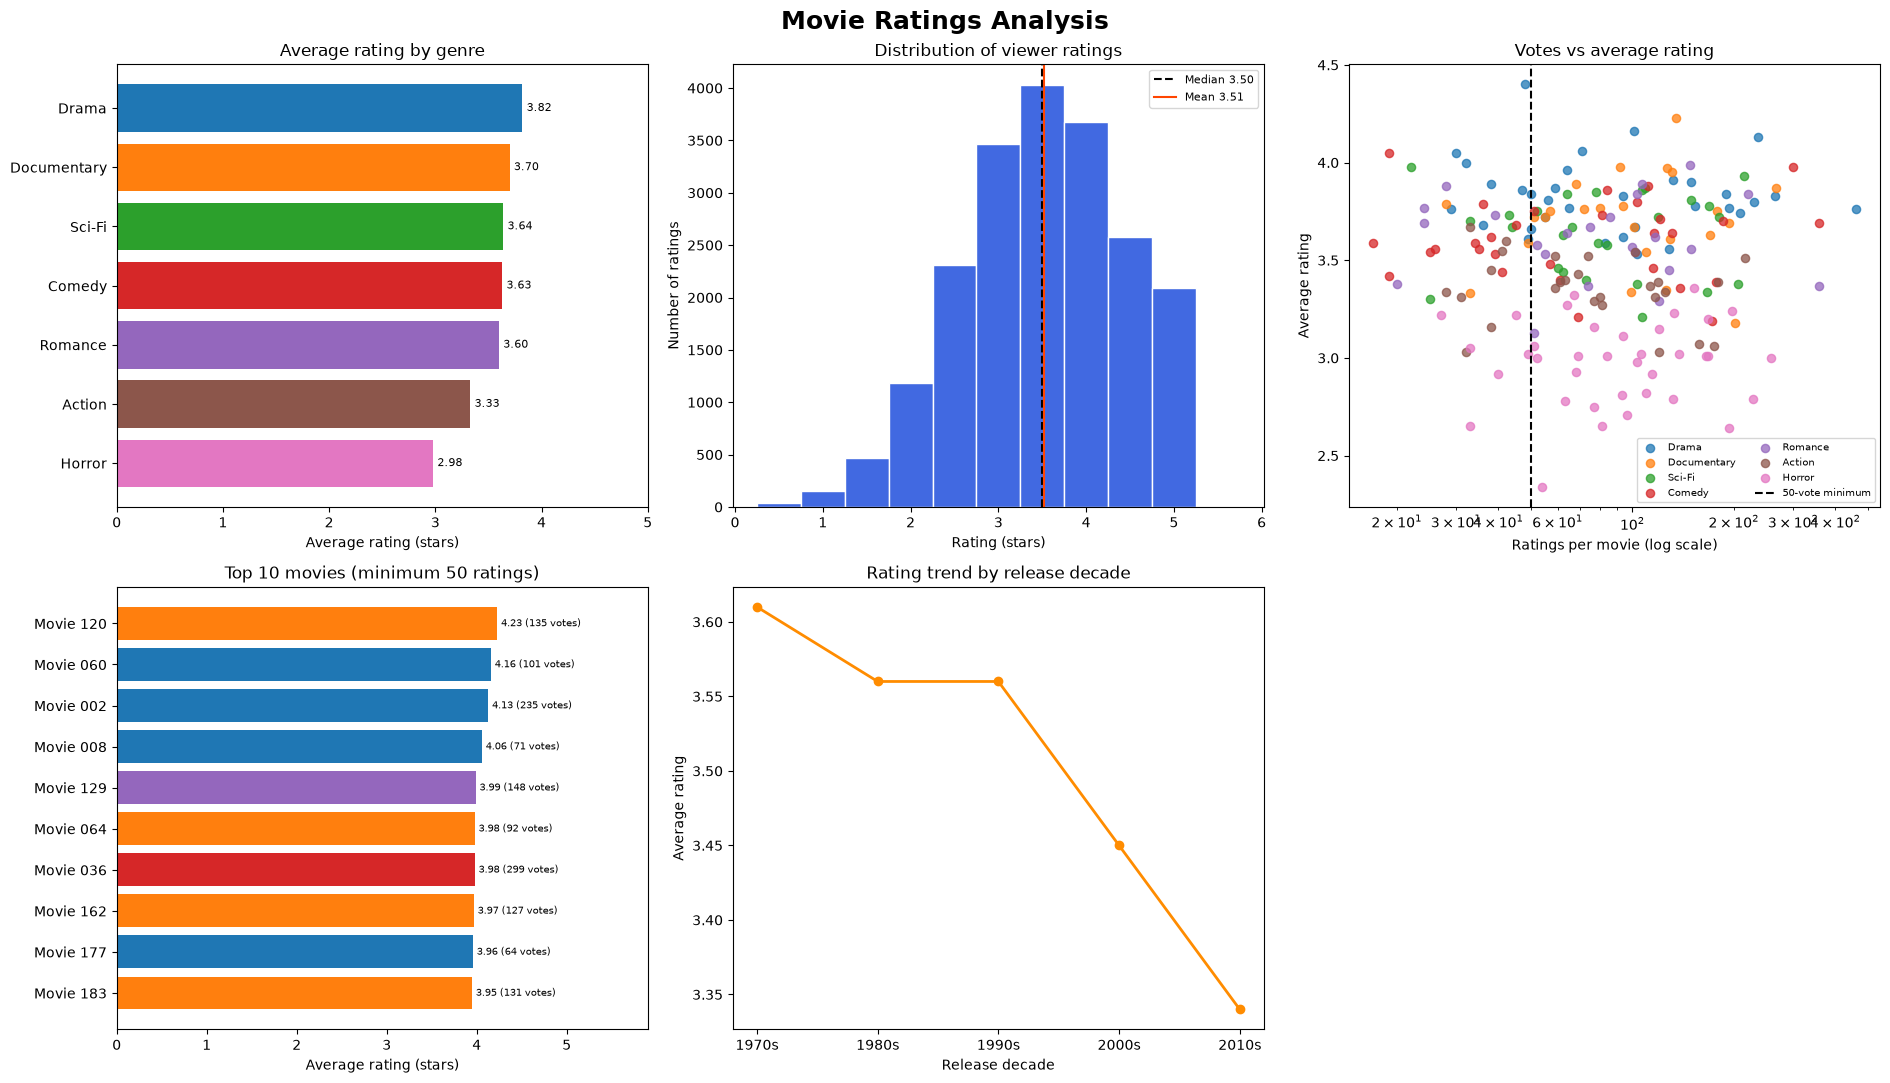

In [10]:
palette = plt.get_cmap("tab10").colors
genre_names = list(genre_summary.index)
genre_colors = {g: palette[i % len(palette)] for i, g in enumerate(genre_names)}
fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# 1) Genre bars
gp = genre_summary.sort_values("average_rating")
axes[0,0].barh(gp.index, gp.average_rating, color=[genre_colors[g] for g in gp.index])
axes[0,0].set(title="Average rating by genre", xlabel="Average rating (stars)", xlim=(0,5))
for i,v in enumerate(gp.average_rating):
    axes[0,0].text(v+0.04, i, f"{v:.2f}", va="center", fontsize=8)

# 2) Rating histogram, mean and median
axes[0,1].hist(df.rating, bins=np.arange(.25,5.76,.5), color="royalblue", edgecolor="white")
mean_rating, median_rating = df.rating.mean(), df.rating.median()
axes[0,1].axvline(median_rating, color="black", linestyle="--", label=f"Median {median_rating:.2f}")
axes[0,1].axvline(mean_rating, color="orangered", label=f"Mean {mean_rating:.2f}")
axes[0,1].set(title="Distribution of viewer ratings", xlabel="Rating (stars)", ylabel="Number of ratings")
axes[0,1].legend(fontsize=8)

# 3) Votes vs average rating, coloured by genre
for g in genre_names:
    s = movie_summary[movie_summary.genre == g]
    axes[0,2].scatter(s.vote_count, s.average_rating, color=genre_colors[g], label=g, alpha=.75, s=35)
axes[0,2].axvline(minimum_votes, color="black", linestyle="--", label="50-vote minimum")
axes[0,2].set_xscale("log")
axes[0,2].set(title="Votes vs average rating", xlabel="Ratings per movie (log scale)", ylabel="Average rating")
axes[0,2].legend(fontsize=7, ncol=2)

# 4) Top 10 bars with vote labels
tp = top10.sort_values("average_rating")
axes[1,0].barh(tp.title, tp.average_rating, color=[genre_colors[g] for g in tp.genre])
axes[1,0].set(title="Top 10 movies (minimum 50 ratings)", xlabel="Average rating (stars)", xlim=(0,5.9))
for i,(_,r) in enumerate(tp.iterrows()):
    axes[1,0].text(r.average_rating+.04, i, f"{r.average_rating:.2f} ({r.vote_count} votes)", va="center", fontsize=7)

# 5) Decade trend
axes[1,1].plot(decade_summary.decade.astype(str)+"s", decade_summary.average_rating,
               color="darkorange", marker="o", linewidth=2)
axes[1,1].set(title="Rating trend by release decade", xlabel="Release decade", ylabel="Average rating")
fig.delaxes(axes[1,2])
fig.suptitle("Movie Ratings Analysis", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.savefig("chart.png", dpi=150, bbox_inches="tight")
plt.show()


In [11]:
best_genre = genre_summary.average_rating.idxmax()
worst_genre = genre_summary.average_rating.idxmin()
best_movie = top10.iloc[0]

results = {
    "project": "Movie Ratings Analysis",
    "dataset_type": "synthetic",
    "total_movies": int(movies.movie_id.nunique()),
    "total_ratings": int(len(df)),
    "overall_average_rating": round(float(df.rating.mean()), 2),
    "highest_rated_genre": str(best_genre),
    "highest_genre_average": round(float(genre_summary.loc[best_genre, "average_rating"]), 2),
    "lowest_rated_genre": str(worst_genre),
    "lowest_genre_average": round(float(genre_summary.loc[worst_genre, "average_rating"]), 2),
    "minimum_votes_for_top10": minimum_votes,
    "top_movie": {"title": str(best_movie.title), "average_rating": float(best_movie.average_rating),
                  "vote_count": int(best_movie.vote_count)},
    "top10_movies": top10[["title","genre","year","average_rating","vote_count"]].to_dict("records"),
    "low_vote_movies_in_unfiltered_top10": int(len(low_vote_top10)),
    "decade_rating_trend": decade_summary.to_dict("records")
}
with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4)

genre_summary.to_csv("genre_analysis.csv")
movie_summary.to_csv("movie_analysis.csv", index=False)
top10.to_csv("top10_movies.csv", index=False)
decade_summary.to_csv("decade_analysis.csv", index=False)

print(json.dumps(results, indent=4))


{
    "project": "Movie Ratings Analysis",
    "dataset_type": "synthetic",
    "total_movies": 200,
    "total_ratings": 20000,
    "overall_average_rating": 3.51,
    "highest_rated_genre": "Drama",
    "highest_genre_average": 3.82,
    "lowest_rated_genre": "Horror",
    "lowest_genre_average": 2.98,
    "minimum_votes_for_top10": 50,
    "top_movie": {
        "title": "Movie 120",
        "average_rating": 4.23,
        "vote_count": 135
    },
    "top10_movies": [
        {
            "title": "Movie 120",
            "genre": "Documentary",
            "year": 2006,
            "average_rating": 4.23,
            "vote_count": 135
        },
        {
            "title": "Movie 060",
            "genre": "Drama",
            "year": 1989,
            "average_rating": 4.16,
            "vote_count": 101
        },
        {
            "title": "Movie 002",
            "genre": "Drama",
            "year": 1977,
            "average_rating": 4.13,
            "vote_count": 2